# Figures and tables of the data descriptor

*High-performance computing patent dataset with full text, structured summaries and semantic embeddings* (HPC-PatentTrace v1.0)

This notebook draws the figures and tables of the data descriptor from the output folder of a full run of `step6_patentsum_pipeline.ipynb`. It needs no GPU and no generation model.

**How to run**

1. Run the pipeline notebook with `PROFILE = "full"`. Its outputs are in `OUTPUT_DIR/full` of that notebook, by default `MyDrive/HPC-PatentTrace/output/full`.
2. Set `RUN_DIR` to that folder and `OUTPUT_DIR` to a folder for the results.
3. Run all cells. Each figure is saved as a 300 dpi PNG and each table as a CSV file in `OUTPUT_DIR`.

In [1]:
#@title Parameters
#@markdown **Run folder**: the output folder of a full run of the pipeline notebook (its OUTPUT_DIR/full).
RUN_DIR = "/content/drive/MyDrive/HPC-PatentTrace/output/full"  #@param {type:"string"}
#@markdown **Output** folder for the figures (PNG, 300 dpi) and tables (CSV).
OUTPUT_DIR = "/content/drive/MyDrive/HPC-PatentTrace/figures_and_tables"  #@param {type:"string"}
#@markdown Compute Table 5 again from the embeddings of the run; otherwise it is read from the run.
RECOMPUTE_TABLE5 = True  #@param {type:"boolean"}

In [2]:
#@title Setup
#@markdown On Google Colab this cell copies the code of the repository; on a local computer, start Jupyter in `colab/` of the repository.
import os, sys
REPO_REF = "main"  #@param {type:"string"}
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/hpc-patent-dataset"):
        !git clone -q --depth 1 --branch {REPO_REF} https://github.com/Taco-Yun/hpc-patent-dataset /content/hpc-patent-dataset
    sys.path.insert(0, "/content/hpc-patent-dataset/colab")
    if RUN_DIR.startswith("/content/drive") or OUTPUT_DIR.startswith("/content/drive"):
        from google.colab import drive
        drive.mount("/content/drive")
else:
    sys.path.insert(0, os.getcwd())
from hpc_patenttrace import open_run, show
from hpc_patenttrace import figures, tables
run = open_run(RUN_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Numbers quoted in the text

Counts of the corpus construction come from the funnel table of section 3.10 of the pipeline; the topic and ownership counts from the release files.

Files: `release/tables/funnel_from_crawler_output.csv`, `release/released_corpus_ids.csv`, `release/cluster_results.csv`, `release/topic_summary.csv`, `release/ownership_events.csv`

In [3]:
#@title Numbers quoted in the text
show(tables.summary_numbers(run, OUTPUT_DIR))

Quantity,Value
query result (publication numbers),"21,947"
removed by the homonym screening,"5,513"
candidates,"16,434"
removed by the completeness filter,"9,276"
five complete fields,"7,158"
excluded by the inclusion rule,623
released records,"6,535"
clusters (HDBSCAN),51
merged topics,25
records without a topic,"1,502"


## Figure 1  Construction of the dataset

(a) Records at each step of the corpus construction; (b) the data layers of each released record.

Files: `release/tables/funnel_from_crawler_output.csv`, `release/released_corpus_ids.csv`, `release/cluster_results.csv`, `release/topic_summary.csv`, `release/embeddings/MANIFEST.csv`, `release/ownership_events.csv`

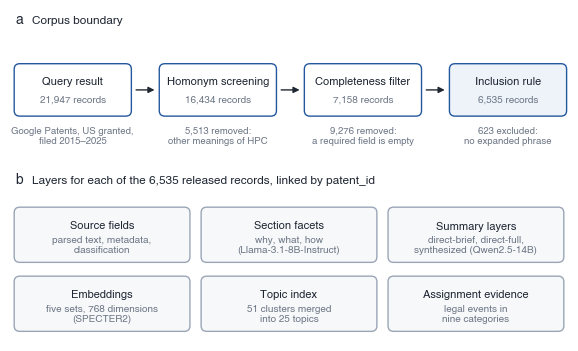

In [4]:
#@title Figure 1
figures.fig1_construction(run, OUTPUT_DIR)

## Table 1  Settings of the three summary layers

File: `release/release_assets/config/generation.json`

In [5]:
#@title Table 1
show(tables.table1_layer_settings(run, OUTPUT_DIR))

Layer,Model calls,Input sections and token budgets,Output
direct-brief,"one call (Qwen2.5-14B-Instruct, bfloat16)","title, abstract; background 800, summary input 400, detailed description 800","≤300 new tokens, 5–7 sentences"
direct-full,"one call (Qwen2.5-14B-Instruct, bfloat16)","title, abstract; background 1,500, summary input 1,500, detailed description 2,000","≤300 new tokens, 5–7 sentences"
synthesized,"facet step (Llama-3.1-8B-Instruct, 4-bit NF4, three calls) and two calls (Qwen2.5-14B-Instruct, bfloat16)","facets from background 1,500, summary input 1,500, detailed description 2,000 (facet model tokens); then title, abstract and the facets","≤300 new tokens, 5–7 sentences"


## Table 2  Last assignment record of the records whose current assignee differs from the original assignee

File: `release/ownership_events.csv` (records with `assignee_changed` true, grouped by `conveyance_type`)

In [6]:
#@title Table 2
show(tables.table2_assignment(run, OUTPUT_DIR))

Category,Records,Share of changes,Transfers title
Assignment (title transfer),378,49.5%,yes
No assignment record,180,23.6%,no
Release of security interest,107,14.0%,no
Security interest (not released),32,4.2%,no
Change of name,26,3.4%,yes
Corrective record,21,2.8%,no
Merger,13,1.7%,yes
Partial transfer,5,0.7%,no
Other,1,0.1%,no


## Table 3  Files of the release folder

Every file that section 9 of the pipeline writes to `release/`, with its rows, columns and size.

File: `release/MANIFEST_release.csv`

In [7]:
#@title Table 3
show(tables.table3_files(run, OUTPUT_DIR), rows=60)

File,Rows,Columns,MB
hpc_patenttrace_corpus.csv,6535,36,781.77
excluded_no_expansion.csv,623,36,75.69
released_corpus_ids.csv,6535,1,0.08
evidence_flags.csv,6535,4,0.17
ownership_events.csv,6535,10,0.91
litigation_family.csv,25,6,0.0
facets.csv,6535,7,14.35
summaries_synthesized.csv,6535,3,15.59
summaries_direct_brief.csv,6535,2,6.82
summaries_direct_full.csv,6535,2,6.85


## Figure 2  Two views of the released patents

The two-dimensional UMAP map of the synthesized embeddings, coloured by the ten largest three-character CPC classes (a) and by the twelve largest merged topics (b).

Files: `umap2d_coords.csv` (section 7.7 of the pipeline), `release/cluster_results.csv`

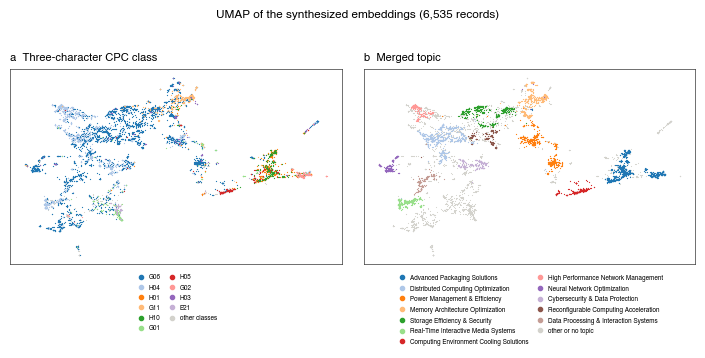

In [8]:
#@title Figure 2
figures.fig2_two_views(run, OUTPUT_DIR)

## Table 5  CPC classification probe on the five embedding sets

Logistic regression on each embedding set predicts the CPC classes of a record (the four-character codes as a multi-label task, the main four-character code and the main three-character class), with a train/test split that keeps patent families together (section 8.9 of the pipeline). The cell computes the probe again from the files of the run and compares the result with the table that the pipeline wrote. Table 4 of the data descriptor describes the validation design in words and has no data.

Files: `release/embeddings/*.parquet`, `release/hpc_patenttrace_corpus.csv` (classes and families), `release/cpc_downstream_comparison.csv`

In [9]:
#@title Table 5
if RECOMPUTE_TABLE5:
    table5, check5 = tables.table5_probe(run, OUTPUT_DIR)
    show(table5)
    show(check5, "Computed again against release/ipc_downstream_comparison.csv")
else:
    show(run.csv("release/ipc_downstream_comparison.csv"))

Representation,Three-character accuracy,Four-character accuracy,At least one label correct,Multi-label micro-F1
abstract,67.2%,55.5%,77.3%,0.6049
fulltext-truncated,66.6%,55.1%,77.6%,0.6077
direct-brief,67.2%,56.5%,77.5%,0.6069
direct-full,66.3%,56.1%,78.3%,0.6094
synthesized,67.3%,56.6%,79.3%,0.6187
Share of the largest class in the training set (no vectors),52.2%,42.7%,—,—


**Computed again against release/ipc_downstream_comparison.csv**

Representation,cpc3_acc,single_acc,any_label_hit,ml_f1_micro,cpc3_acc (pipeline),single_acc (pipeline),any_label_hit (pipeline),ml_f1_micro (pipeline),same
abstract,0.6717,0.5547,0.7728,0.6049,0.6717,0.5547,0.7728,0.6049,yes
fulltext-truncated,0.6664,0.5509,0.7758,0.6077,0.6664,0.5509,0.7758,0.6077,yes
direct-brief,0.6725,0.5653,0.7751,0.6069,0.6725,0.5653,0.7751,0.6069,yes
direct-full,0.6626,0.5608,0.7826,0.6094,0.6626,0.5608,0.7826,0.6094,yes
synthesized,0.6732,0.566,0.7932,0.6187,0.6732,0.566,0.7932,0.6187,yes


### Notes

- The code of the figures and tables is in `colab/hpc_patenttrace/figures.py` and `tables.py`.
- `step6_patentsum_pipeline.ipynb` builds the run folder that this notebook reads, from the crawler output.